# New York City Airbnb: asking prices, room types and availability

This project compares listing prices and availability in the supplied 2019 New York snapshot. It uses medians alongside averages because a few unusually expensive listings can distort the mean. Asking prices are not assumed to be realised booking prices.

## Data and scope

Source: [new-york-city-airbnb-open-data](https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data). This report uses the uploaded snapshot, not live data.

`id` identifies a listing and `host_id` its host. `neighbourhood_group` is the borough, `neighbourhood` the local area, and latitude/longitude locate the listing. `room_type` describes the accommodation; `price` is the listed nightly price in USD. `minimum_nights` is the minimum requested stay. `number_of_reviews`, `last_review` and `reviews_per_month` describe reviews. `calculated_host_listings_count` is a supplied host listing count and `availability_365` is calendar availability over a year. `name` and `host_name` are text labels.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def data_path(filename):
    # Works after extracting this ZIP, or after attaching its data on Kaggle.
    for folder in (Path("data"), Path(".")):
        candidate = folder / filename
        if candidate.is_file():
            return candidate
    kaggle = Path("/kaggle/input")
    matches = sorted(kaggle.rglob(filename)) if kaggle.exists() else []
    if len(matches) == 1:
        return matches[0]
    raise FileNotFoundError(f"Place {filename} in data/, or attach its dataset on Kaggle. Found {len(matches)} Kaggle matches.")

In [2]:
raw = pd.read_csv(data_path("AB_NYC_2019.csv"))
print(f"Raw listings: {len(raw):,}; columns: {raw.shape[1]}")
assert len(raw)>=150 and raw.shape[1]>=3
display(raw.drop(columns=["name","host_name"]).head()); display(raw.isna().sum().to_frame("missing"))

Raw listings: 48,895; columns: 16


,id,host_id,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,2787,Brooklyn,Kensington,40.647,-73.972,Private room,149,1,9,2018-10-19,0.210,6,365
1,2595,2845,Manhattan,Midtown,40.754,-73.984,Entire home/apt,225,1,45,2019-05-21,0.380,2,355
2,3647,4632,Manhattan,Harlem,40.809,-73.942,Private room,150,3,0,NaN,NaN,1,365
3,3831,4869,Brooklyn,Clinton Hill,40.685,-73.960,Entire home/apt,89,1,270,2019-07-05,4.640,1,194
4,5022,7192,Manhattan,East Harlem,40.799,-73.944,Entire home/apt,80,10,9,2018-11-19,0.100,1,0


,missing
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


## Cleaning prices and keeping unusual listings visible

Exact duplicate rows are removed and unique listing IDs are checked. Prices at zero or below are excluded from price comparisons because they are not usable nightly asking prices. Other listing analyses retain those records. Availability outside 0–365 and impossible minimum stays are flagged as missing. Missing monthly-review rates stay missing; a blank review rate is not silently changed to zero. High prices remain in the calculations, with a restricted display range clearly labelled where used.

Listings excluded from price comparisons: 11
Listings with zero reviews: 10,052; missing monthly review rates: 10,052


,count,mean,std,min,25%,50%,75%,max
price,"48,895.000",152.721,240.154,0.000,69.000,106.000,175.000,"10,000.000"
minimum_nights,"48,895.000",7.030,20.511,1.000,1.000,3.000,5.000,"1,250.000"
number_of_reviews,"48,895.000",23.274,44.551,0.000,1.000,5.000,24.000,629.000
reviews_per_month,"38,843.000",1.373,1.680,0.010,0.190,0.720,2.020,58.500
availability_365,"48,895.000",112.781,131.622,0.000,0.000,45.000,227.000,365.000


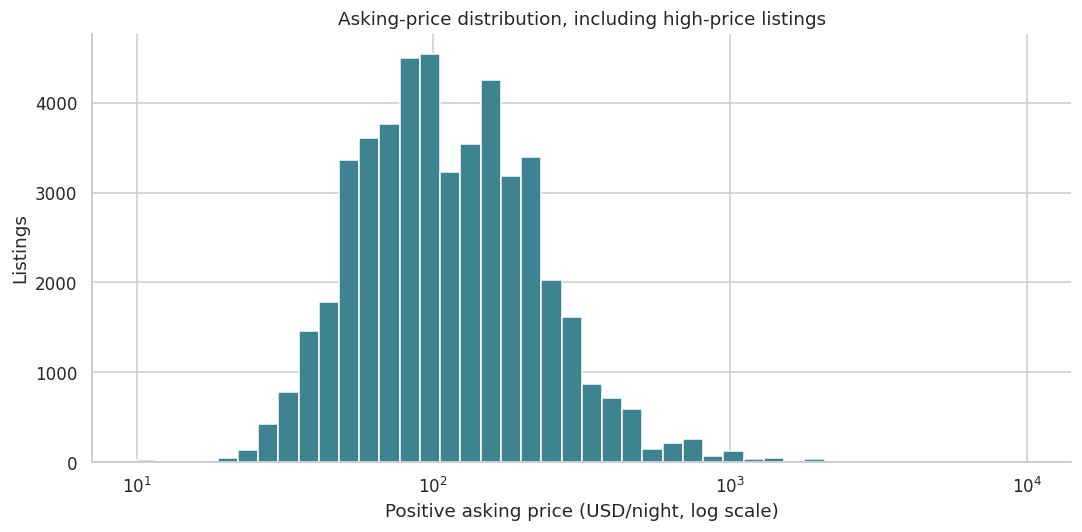

In [3]:
df = raw.drop_duplicates().copy()
assert not df.id.duplicated().any()
df["last_review"] = pd.to_datetime(df.last_review,errors="coerce")
for col in ["price","minimum_nights","number_of_reviews","reviews_per_month","availability_365","latitude","longitude"]:
    df[col] = pd.to_numeric(df[col],errors="coerce")
df.loc[~df.availability_365.between(0,365),"availability_365"] = np.nan
df.loc[df.minimum_nights<1,"minimum_nights"] = np.nan
df.loc[df.number_of_reviews<0,"number_of_reviews"] = np.nan
df.loc[df.reviews_per_month<0,"reviews_per_month"] = np.nan
priced = df[df.price>0].copy()
print(f"Listings excluded from price comparisons: {len(df)-len(priced)}")
print(f"Listings with zero reviews: {df.number_of_reviews.eq(0).sum():,}; missing monthly review rates: {df.reviews_per_month.isna().sum():,}")
display(df[["price","minimum_nights","number_of_reviews","reviews_per_month","availability_365"]].describe().T)
plt.hist(priced.price,bins=np.geomspace(priced.price.min(),priced.price.max()*1.001,45),color="#3d8392")
plt.xscale("log"); plt.xlabel("Positive asking price (USD/night, log scale)"); plt.ylabel("Listings")
plt.title("Asking-price distribution, including high-price listings"); plt.tight_layout(); plt.show()

## 1. How do typical asking prices differ across boroughs?

`groupby()` and `agg()` report listing counts, mean, median and quartiles. The median is used in the chart so a small number of expensive listings does not dominate the comparison.

,count,median,mean,q25,q75
neighbourhood_group,,,,,
Manhattan,21660,150.000,196.885,95.000,220.000
Brooklyn,20095,90.000,124.439,60.000,150.000
Queens,5666,75.000,99.518,50.000,110.000
Staten Island,373,75.000,114.812,50.000,110.000
Bronx,1090,65.000,87.577,45.000,99.000


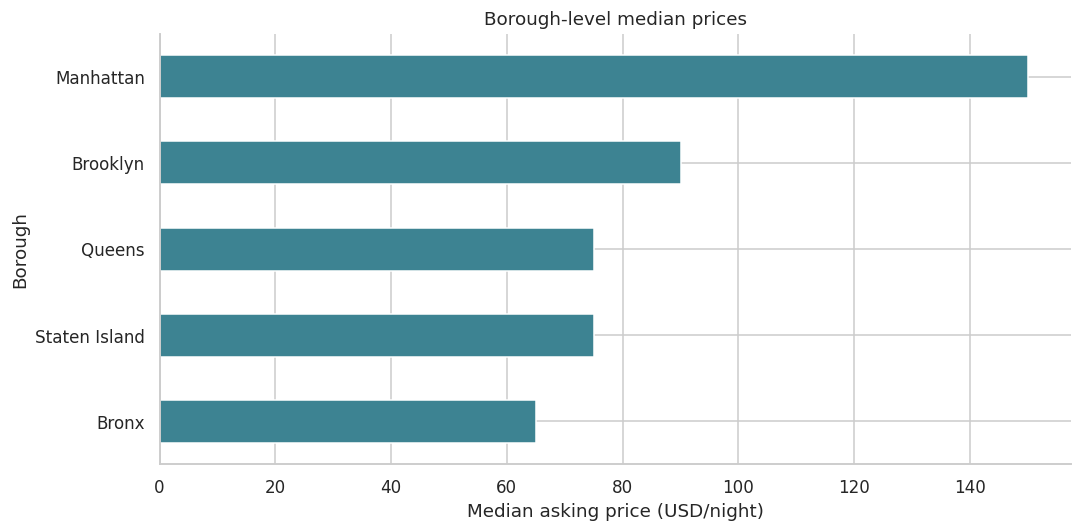

In [4]:
borough = priced.groupby("neighbourhood_group").price.agg(count="count",median="median",mean="mean",q25=lambda x:x.quantile(.25),q75=lambda x:x.quantile(.75)).sort_values("median",ascending=False)
display(borough)
borough["median"].sort_values().plot.barh(color="#3d8392")
plt.xlabel("Median asking price (USD/night)"); plt.ylabel("Borough")
plt.title("Borough-level median prices"); plt.tight_layout(); plt.show()

**Answer.** Manhattan has the highest borough median asking price ($150 per night), based on 21,660 positive-price listings. Borough room-type mix differs, so this overall comparison does not isolate location alone.

## 2. Does the room-type mix explain part of the borough difference?

`pivot_table()` calculates median prices for each borough-room combination, while `crosstab()` shows the number of listings behind those medians. Comparing room types within boroughs gives more detail than a single borough average.

room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Bronx,100.000,54.000,40.000
Brooklyn,145.000,65.000,36.000
Manhattan,191.000,90.000,69.000
Queens,120.000,60.000,37.000
Staten Island,100.000,50.000,30.000


room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Bronx,379,651,60
Brooklyn,9558,10126,411
Manhattan,13198,7982,480
Queens,2096,3372,198
Staten Island,176,188,9


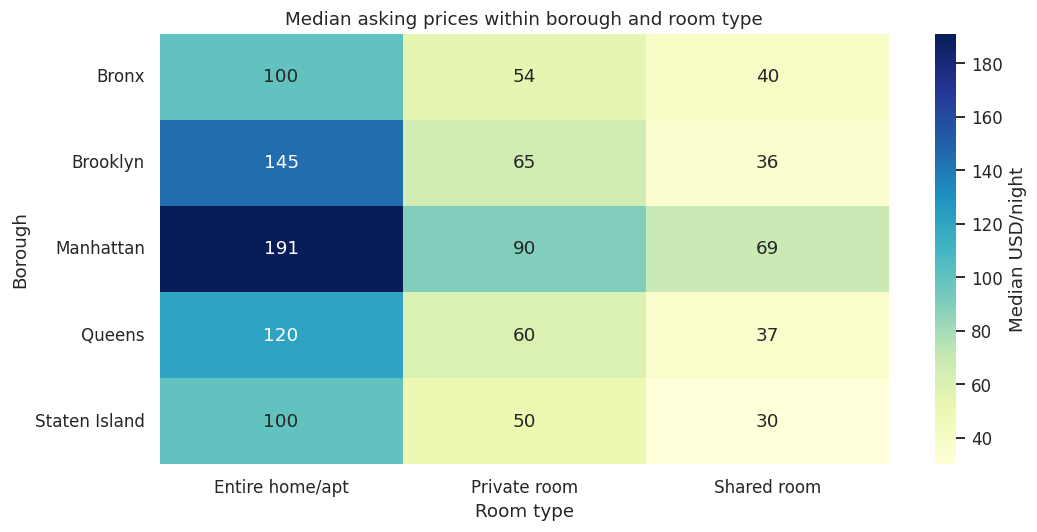

In [5]:
room_prices = priced.pivot_table(index="neighbourhood_group",columns="room_type",values="price",aggfunc="median")
room_counts = pd.crosstab(priced.neighbourhood_group,priced.room_type)
display(room_prices); display(room_counts)
sns.heatmap(room_prices,annot=True,fmt=".0f",cmap="YlGnBu",cbar_kws={"label":"Median USD/night"})
plt.xlabel("Room type"); plt.ylabel("Borough"); plt.title("Median asking prices within borough and room type")
plt.tight_layout(); plt.show()
room_overall = priced.groupby("room_type").price.median()

**Answer.** Across the snapshot, Entire home/apt has the highest room-type median ($160), while Shared room has the lowest ($45). The within-borough table confirms why room type should be considered alongside location; it does not quantify a causal explanation of the borough gap.

## 3. How does calendar availability differ by room type?

The full valid range of availability is retained. `boxplot()` shows the spread and `median()` gives the typical listing. Zero availability can mean booked nights, blocked dates or an inactive calendar, so it is not treated as 100% occupancy.

,count,median,mean,min,max
room_type,,,,,
Entire home/apt,25409,42.000,111.920,0.000,365.000
Private room,22326,45.000,111.204,0.000,365.000
Shared room,1160,90.000,162.001,0.000,365.000


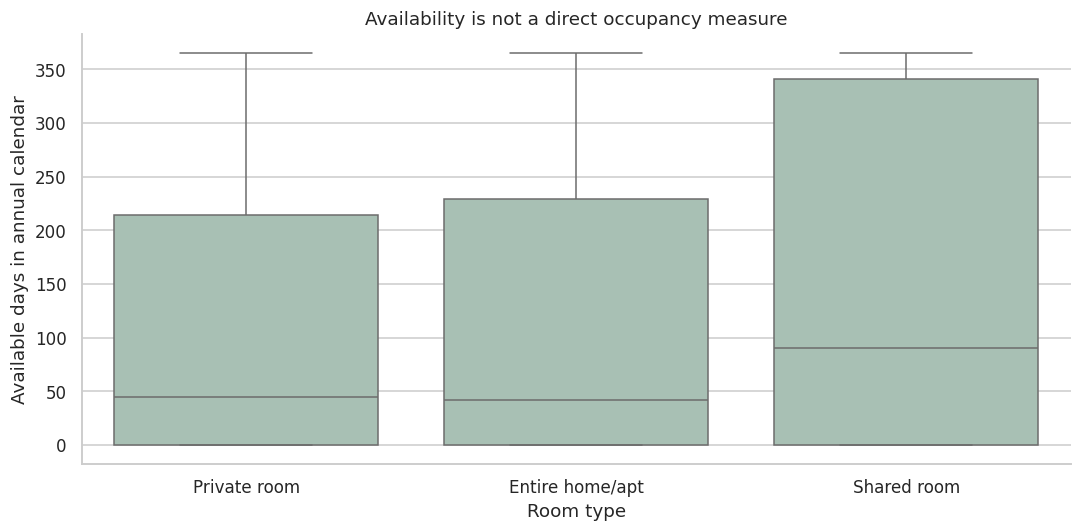

In [6]:
availability = df.groupby("room_type").availability_365.agg(["count","median","mean","min","max"])
display(availability)
sns.boxplot(data=df,x="room_type",y="availability_365",color="#a4c4b4")
plt.xlabel("Room type"); plt.ylabel("Available days in annual calendar")
plt.title("Availability is not a direct occupancy measure"); plt.tight_layout(); plt.show()

**Answer.** Shared room has the highest median reported availability (90 days). Across all listings, 35.9% show zero available days. Neither number establishes booking demand or host income.

## 4. Are higher asking prices associated with more reviews per month?

The calculation uses positive-price listings with a reported monthly-review rate. Spearman correlation measures ordering without assuming a straight-line relationship. The scatter plot is limited to prices up to the 99th percentile for readability, but the correlation uses the complete eligible subset.

,count,mean,std,min,25%,50%,75%,max
price,"38,833.000",142.355,196.958,10.000,69.000,101.000,170.000,"10,000.000"
reviews_per_month,"38,833.000",1.373,1.680,0.010,0.190,0.720,2.020,58.500


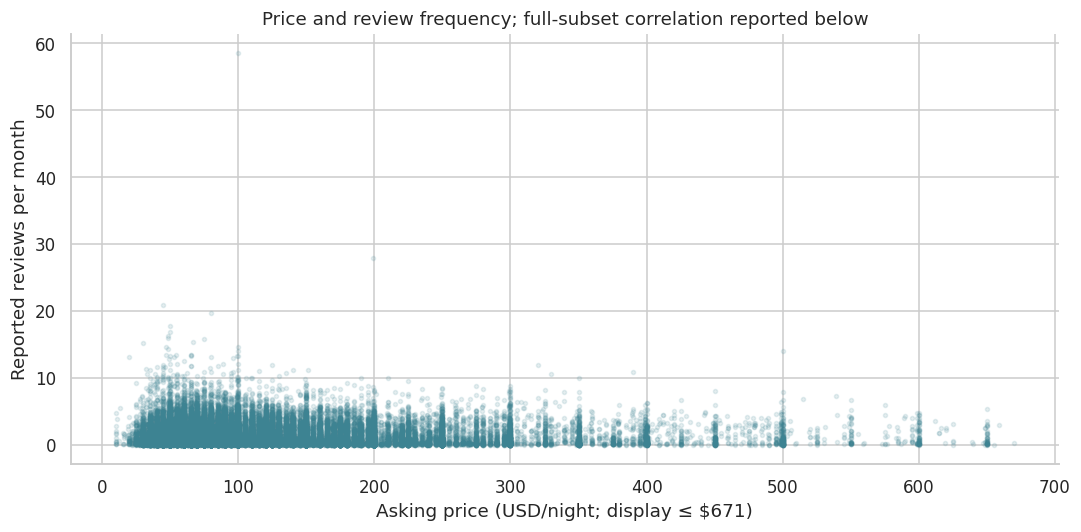

In [7]:
reviewed = priced.dropna(subset=["reviews_per_month"]).copy()
rho = reviewed.price.corr(reviewed.reviews_per_month,method="spearman")
display(reviewed[["price","reviews_per_month"]].describe().T)
cutoff = reviewed.price.quantile(.99)
display_rows = reviewed[reviewed.price<=cutoff]
plt.scatter(display_rows.price,display_rows.reviews_per_month,s=7,alpha=.13,color="#3d8392")
plt.xlabel(f"Asking price (USD/night; display ≤ ${cutoff:.0f})"); plt.ylabel("Reported reviews per month")
plt.title("Price and review frequency; full-subset correlation reported below")
plt.tight_layout(); plt.show()

**Answer.** The rank correlation is -0.018 across 38,833 listings with both values. Reviews are an incomplete proxy for stays, and missing monthly-review rates are excluded. This relationship cannot establish whether changing a price would change bookings.

## 5. How concentrated are listings among hosts in this snapshot?

`groupby(host_id).size()` counts distinct listings per host directly from this file. This avoids relying on a supplied count whose scope might differ. The share belonging to hosts with multiple listings is a share of listings, not a share of hosts.

,hosts
id,
1,32303
2,3329
3–5,1480
6–10,251
11+,94


,listings_per_host
count,"37,457.000"
mean,1.305
std,2.761
min,1.000
25%,1.000
50%,1.000
75%,1.000
max,327.000


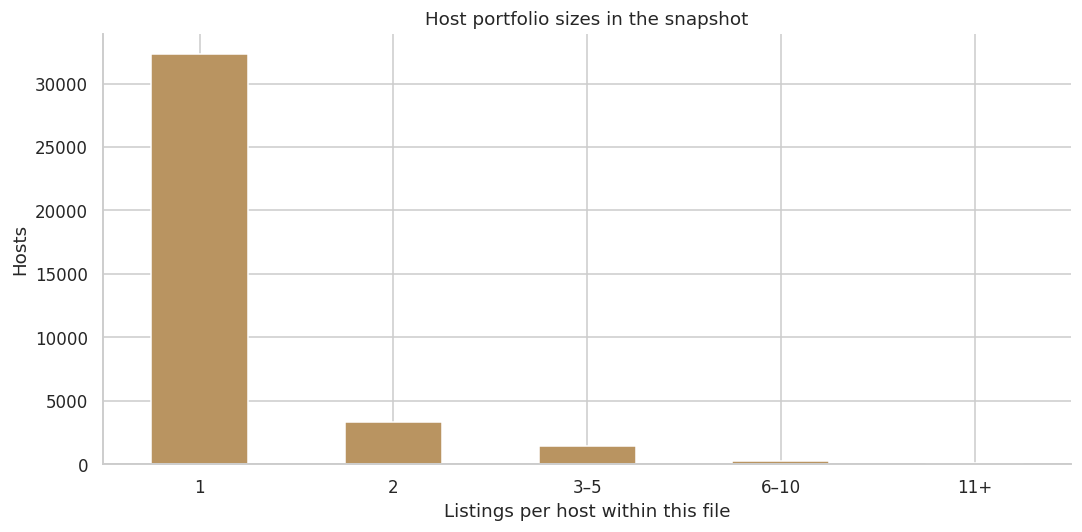

In [8]:
host_sizes = df.groupby("host_id").id.nunique()
multi_listing_share = host_sizes[host_sizes>=2].sum()/host_sizes.sum()*100
top_host_share = host_sizes.nlargest(10).sum()/host_sizes.sum()*100
host_bands = pd.cut(host_sizes,bins=[0,1,2,5,10,np.inf],labels=["1","2","3–5","6–10","11+"])
host_distribution = host_bands.value_counts(sort=False)
display(host_distribution.to_frame("hosts"))
display(host_sizes.describe().to_frame("listings_per_host"))
host_distribution.plot.bar(color="#b99461",rot=0)
plt.xlabel("Listings per host within this file"); plt.ylabel("Hosts")
plt.title("Host portfolio sizes in the snapshot"); plt.tight_layout(); plt.show()

**Answer.** Hosts with at least two listings account for 33.9% of listed properties. The ten largest host portfolios account for 2.6%. A multi-listing host may manage properties for others, so listing counts alone do not establish ownership or business status.

## Conclusion

Manhattan has the highest borough median asking price at $150 per night. Room type matters within boroughs, and the price–monthly-review rank correlation is close to zero at -0.018. Hosts with multiple listings account for 33.9% of properties in the snapshot.

Room type and borough should be considered together when comparing asking prices. Price outliers affect averages, and availability and review measures need careful interpretation. Host portfolio counts describe concentration in this file without assuming ownership or income.